In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size':12, 'axes.labelsize':12, 'font.sans-serif':'Verdana'})

In [2]:
# Define scaling factor in arbitrary units
cscale = 1

# Independent variable - will be y for parabola and hyperbola, x for ellipse
ind = np.linspace(-4, 4, num=201, endpoint=True)

#### Function to plot hyperbolic orbit

In [3]:
def plot_hyperbola(c, eps, y, ax):
    # Define constants
    alpha = c / (eps**2 - 1)
    beta = c / np.sqrt(eps**2 - 1)
    delta = c*eps / (eps**2 - 1)
    # Print orbital constants
    print(f"Hyperbola orbital constants for c={c:.3f}, eps={eps:.3f}")
    print(f"alpha: {alpha:.3f}, beta: {beta:.3f}, delta: {delta:.3f}")
    focus = delta - alpha*eps # Should be zero, the way our coordinate system is set up
    # Sanity check that the focus of the hyperbola is at x=0
    print('\nChecking that focus is at zero:', np.allclose(focus, 0))
    # Create vector of y values, which will be independent variable
    # Calculate left branch of hyperbola
    hyp = -np.sqrt(alpha**2 * (1 + y**2/beta**2)) + delta
    # Sanity check that orbit follows (x-delta)^2/alpha^2 - y^2/beta^2 = 1
    print(r"Sanity check that $\frac{(x-\delta)^2}{\alpha^2} - \frac{y^2}{\beta^2} = 1$:", 
          np.allclose((hyp - delta)**2 / alpha**2 - y**2 / beta**2, 1))
    # Now plot
    ax.plot(hyp, y, color='dodgerblue')
    ax.scatter([delta], [0], color='darkorchid', s=40)
    ax.scatter([delta-alpha], [0], color='mediumseagreen', s=40)
    ax.scatter([focus], [0], color='coral', marker='*', s=200)
    ax.scatter([0, 0], [c, -c], color='crimson', s=40)
    ax.set_xticks([-2, -1, 0, 1, 2])
    ax.text(delta, -0.12, r"$(\delta, 0)$", horizontalalignment='left', 
            verticalalignment='top', color='darkorchid')
    ax.text(delta-alpha, 0.15, r"$(\delta-\alpha, 0)$", horizontalalignment='left', 
            verticalalignment='bottom', color='mediumseagreen')
    ax.text(-0.1, -0.1, 'Star', horizontalalignment='right', 
            verticalalignment='top', color='coral')
    ax.text(0, -c-0.1, r"$(0, -c)$", horizontalalignment='left', 
            verticalalignment='top', color='crimson')
    ax.text(0, c+0.1, r"$(0, c)$", horizontalalignment='left', 
            verticalalignment='bottom', color='crimson')
    ax.set_xlabel('x (arbitrary units)')
    ax.set_ylabel('y (arbitrary units)')
    ax.set_title('Hyperbolic orbit')
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-3, 3)
    ax.set_aspect('equal')
    ax.grid(color='0.85')

Hyperbola orbital constants for c=1.000, eps=1.500
alpha: 0.800, beta: 0.894, delta: 1.200

Checking that focus is at zero: True
Sanity check that $\frac{(x-\delta)^2}{\alpha^2} - \frac{y^2}{\beta^2} = 1$: True


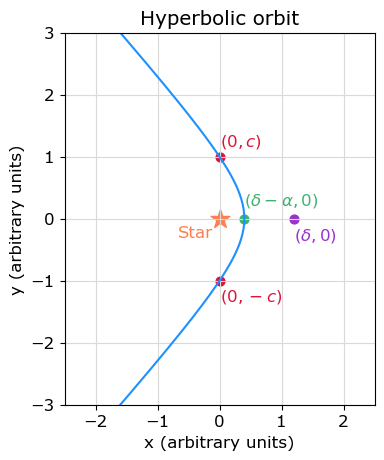

In [4]:
fig, ax = plt.subplots(1, 1, figsize=(4, 6))
plot_hyperbola(cscale, 1.5, ind, ax)

#### Function to plot parabolic orbit

In [5]:
def plot_parabola(c, y, ax):
    xpara = (-0.5/c)*y**2 + 0.5*c
    # Check that x(y) satisfies 2cx = c^2 - y^2
    print(r"Sanity check that $x(y)$ satisfies $2cx = c^2 - y^2$:", 
          np.allclose(xpara, (c**2 - y**2)/ (2*c)))
    yroots = [-c, c]
    xperi = c/2 # perihelion
    ax.plot(xpara, y, color='dodgerblue')
    ax.scatter([0], [0], color='coral', marker='*', s=200)
    ax.scatter([0, 0], yroots, color='crimson', s=40)
    ax.scatter([c/2], [0], color='mediumseagreen')
    ax.set_xticks([-2, -1, 0, 1, 2])
    ax.text(0, c+0.1, r"$(0, c)$", horizontalalignment='left', 
            verticalalignment='bottom', color='crimson')
    ax.text(0, -c-0.1, r"$(0, -c)$", horizontalalignment='left', 
            verticalalignment='top', color='crimson')
    ax.text(c/2+0.1, 0, r"$(c/2, 0)$", horizontalalignment='left', 
            verticalalignment='bottom', color='mediumseagreen')
    ax.text(-0.1, -0.1, 'Star', horizontalalignment='right', 
            verticalalignment='top', color='coral')
    ax.set_xlabel('x (arbitrary units)')
    # ax.set_ylabel('y (arbitrary units)')
    ax.set_title('Parabolic orbit')
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-3, 3)
    ax.set_aspect('equal')
    ax.grid(color='0.85')

Sanity check that $x(y)$ satisfies $2cx = c^2 - y^2$: True


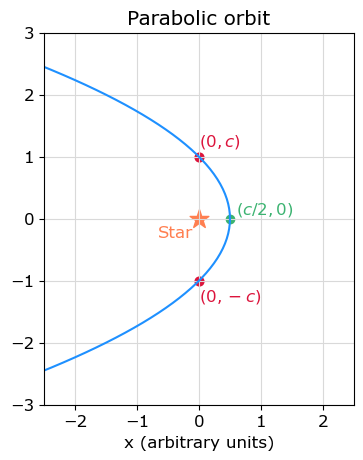

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(4, 6))
plot_parabola(cscale, ind, ax)

#### Elliptical orbit

In [14]:
def plot_ellipse(c, e, ax):
    # Define constants
    a = c/(1-e**2)
    b = c/np.sqrt(1-e**2)
    d = c*e/(1-e**2)
    peri = a * (1-e)
    ap = -a * (1+e)
    # full-circle phi values
    phi = np.linspace(0, 2*np.pi, num=201, endpoint=True)
    r = c / (1 + e*np.cos(phi))
    x = r*np.cos(phi)
    y = r*np.sin(phi)
    # Plot
    ax.plot(x, y, color='dodgerblue')
    ax.scatter([0], [0], marker='*', color='coral', s=200)
    ax.scatter([0, 0], [c, -c], color='crimson', s=40)
    ax.scatter([-d, -d], [b, -b], color='blue', s=40)
    ax.scatter([-d], [0], color='mediumseagreen', s=40)
    ax.scatter([peri, ap], [0, 0], color='darkorchid', s=40)
    ax.text(-0.1, -0.15, 'Star', horizontalalignment='center', 
            verticalalignment='top', color='coral')
    ax.text(0, c+0.1, r"$(0, c)$", horizontalalignment='left', 
            verticalalignment='bottom', color='crimson')
    ax.text(0, -c-0.1, r"$(0,-c)$", horizontalalignment='left', 
            verticalalignment='top', color='crimson')
    ax.text(-d-0.1, 0, r"$(-d, 0)$", color='mediumseagreen', horizontalalignment='right',
           verticalalignment='bottom')
    ax.text(-d, b+0.1, r"$(0, b)$", color='blue', horizontalalignment='right',
           verticalalignment='bottom')
    ax.text(-d, -b-0.1, r"$(0,-b)$", color='blue', horizontalalignment='right',
           verticalalignment='top')
    ax.text(peri, -0.1, r"$(a(1-e), 0)$", color='darkorchid', fontsize='small',
            horizontalalignment='left', verticalalignment='top')
    ax.text(ap, -0.1, r"$(-a(1+e), 0)$", color='darkorchid', fontsize='small',
            horizontalalignment='right', verticalalignment='top')
    ax.set_aspect('equal')
    ax.set_xlim(-3.25, 2)
    ax.set_ylim(-1.5, 1.5)
    ax.set_yticks([-1, 0, 1])
    ax.set_xlabel('x (arbitrary units)')
    ax.set_ylabel('y (arbitrary units)')
    ax.set_title('Elliptical orbit')
    ax.grid(color='0.85')

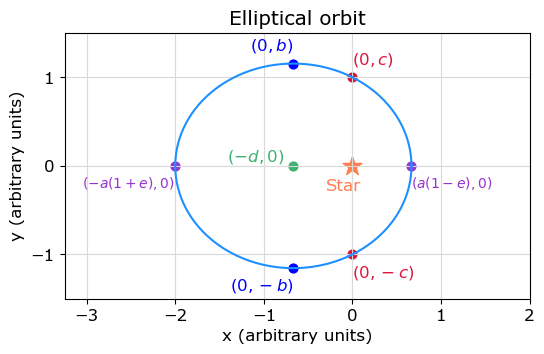

In [15]:
fig, ax = plt.subplots(1, 1, figsize=(6, 4))
plot_ellipse(cscale, 0.5, ax)

#### Put all the plots together

Hyperbola orbital constants for c=1.000, eps=1.500
alpha: 0.800, beta: 0.894, delta: 1.200

Checking that focus is at zero: True
Sanity check that $\frac{(x-\delta)^2}{\alpha^2} - \frac{y^2}{\beta^2} = 1$: True
Sanity check that $x(y)$ satisfies $2cx = c^2 - y^2$: True


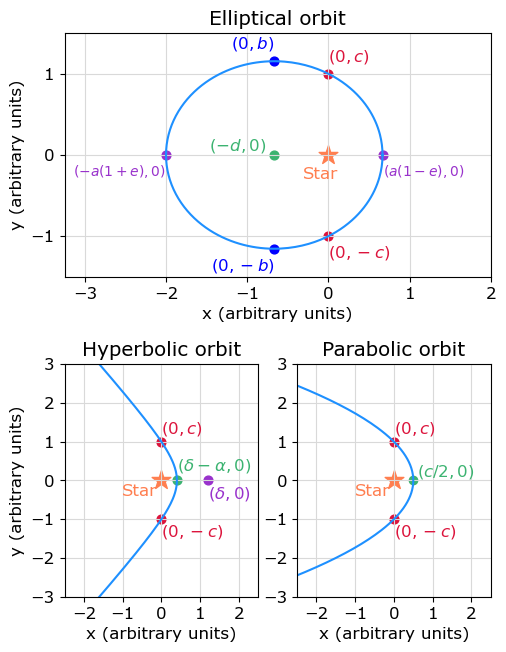

In [16]:
fig = plt.figure(figsize=(5.5, 7.75))
axs = fig.subplot_mosaic([["a", "a"],
                          ["b", "c"]])
plot_ellipse(cscale, 0.5, axs["a"])
plot_hyperbola(cscale, 1.5, ind, axs["b"])
plot_parabola(cscale, ind, axs["c"])
# fig.tight_layout()
plt.savefig('Kepler_orbits.png')